# Project : Online Shoppers Purchasing Intention

## 1. Introduction

### 1.1 Motivation

Understanding online customer behavior is an important challenge for e-commerce platforms. Predicting whether a visitor will make a purchase can help businesses understand shopping behavior and improve their online experience.

### 1.2 Objective

Predict whether an online shopping session will result in a purchase using the Online Shoppers Purchasing Intention dataset.

### 1.3 Worflow 

1) Exploring and preprocessing dataset
2) Train a classification model
3) Evaluate and compare model performance
4) Interpret the results

## 2. Imports and Dataset load

### 2.1 Imports

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

### 2.2 Load the CSV

In [27]:
df = pd.read_csv("data/online_shoppers_intention.csv")

print("Dataset shape:", df.shape)
display(df.head())
display(df.info())

Dataset shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

None

### 2.3 Structure of the dataset

In [28]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Administrative,12330.0,NaN,NaN,NaN,2.315166,3.321784,0.0,0.0,1.0,4.0,27.0
Administrative_Duration,12330.0,NaN,NaN,NaN,80.818611,176.779107,0.0,0.0,7.5,93.25625,3398.75
Informational,12330.0,NaN,NaN,NaN,0.503569,1.270156,0.0,0.0,0.0,0.0,24.0
Informational_Duration,12330.0,NaN,NaN,NaN,34.472398,140.749294,0.0,0.0,0.0,0.0,2549.375
ProductRelated,12330.0,NaN,NaN,NaN,31.731468,44.475503,0.0,7.0,18.0,38.0,705.0
ProductRelated_Duration,12330.0,NaN,NaN,NaN,1194.74622,1913.669288,0.0,184.1375,598.936905,1464.157214,63973.52223
BounceRates,12330.0,NaN,NaN,NaN,0.022191,0.048488,0.0,0.0,0.003112,0.016813,0.2
ExitRates,12330.0,NaN,NaN,NaN,0.043073,0.048597,0.0,0.014286,0.025156,0.05,0.2
PageValues,12330.0,NaN,NaN,NaN,5.889258,18.568437,0.0,0.0,0.0,0.0,361.763742
SpecialDay,12330.0,NaN,NaN,NaN,0.061427,0.198917,0.0,0.0,0.0,0.0,1.0


## 3. Data quality

### 3.1 Missing and duplicate values

In [29]:
print("Duplicate rows:", df.duplicated().sum())
print("\nMissing values per column:")
display(df.isna().sum().sort_values(ascending=False))

Duplicate rows: 125

Missing values per column:


Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64

### 3.2 Inspect target 

In [30]:
print("Revenue values:")
display(df["Revenue"].value_counts(dropna=False))

print("\nData types:")
display(df.dtypes.to_frame(name="Data type"))

Revenue values:


Revenue
False    10422
True      1908
Name: count, dtype: int64


Data types:


,Data type
Administrative,int64
Administrative_Duration,float64
Informational,int64
Informational_Duration,float64
ProductRelated,int64
ProductRelated_Duration,float64
BounceRates,float64
ExitRates,float64
PageValues,float64
SpecialDay,float64


## 4. Data analysis

### 4.1 Distribution of purchase outcomes

Revenue
False    10422
True      1908
Name: Count, dtype: int64

Revenue
False    84.53
True     15.47
Name: Percentage, dtype: float64

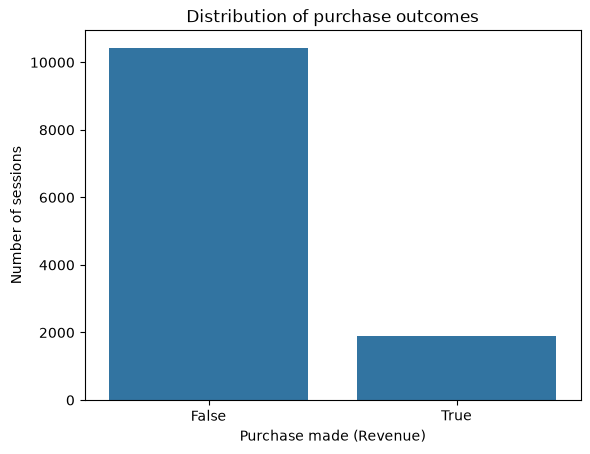

In [31]:
display(df["Revenue"].value_counts().rename("Count"))
display((df["Revenue"].value_counts(normalize=True) * 100).rename("Percentage").round(2))

sns.countplot(data=df, x="Revenue")
plt.title("Distribution of purchase outcomes")
plt.xlabel("Purchase made (Revenue)")
plt.ylabel("Number of sessions")
plt.show()

### 4.2 Explore sessions by visitors and months

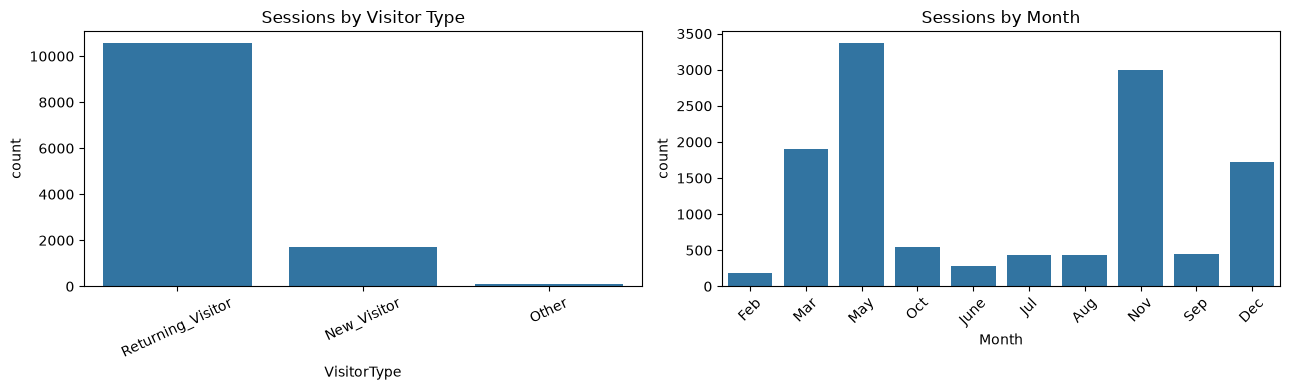

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.countplot(data=df, x="VisitorType", ax=axes[0])
axes[0].set_title("Sessions by Visitor Type")
axes[0].tick_params(axis="x", rotation=25)

sns.countplot(data=df, x="Month", ax=axes[1])
axes[1].set_title("Sessions by Month")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

### 4.3 Purchase rate by category (visitor/month)

In [33]:
visitor_rates = df.groupby("VisitorType")["Revenue"].mean().sort_values(ascending=False)
month_rates = df.groupby("Month")["Revenue"].mean().sort_values(ascending=False)

display(visitor_rates.rename("Purchase rate").to_frame())
display(month_rates.rename("Purchase rate").to_frame())

,Purchase rate
VisitorType,
New_Visitor,0.249115
Other,0.188235
Returning_Visitor,0.139323


,Purchase rate
Month,
Nov,0.253502
Oct,0.209472
Sep,0.191964
Aug,0.175520
Jul,0.152778
Dec,0.125072
May,0.108502
June,0.100694
Mar,0.100682


### 4.4 Selection of features for the visualisation

In [34]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()

display(df[numeric_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.315166,3.321784,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,12330.0,80.818611,176.779107,0.0,0.000000,7.500000,93.256250,3398.750000
Informational,12330.0,0.503569,1.270156,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,12330.0,34.472398,140.749294,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,12330.0,31.731468,44.475503,0.0,7.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,12330.0,1194.746220,1913.669288,0.0,184.137500,598.936905,1464.157214,63973.522230
BounceRates,12330.0,0.022191,0.048488,0.0,0.000000,0.003112,0.016813,0.200000
ExitRates,12330.0,0.043073,0.048597,0.0,0.014286,0.025156,0.050000,0.200000
PageValues,12330.0,5.889258,18.568437,0.0,0.000000,0.000000,0.000000,361.763742
SpecialDay,12330.0,0.061427,0.198917,0.0,0.000000,0.000000,0.000000,1.000000


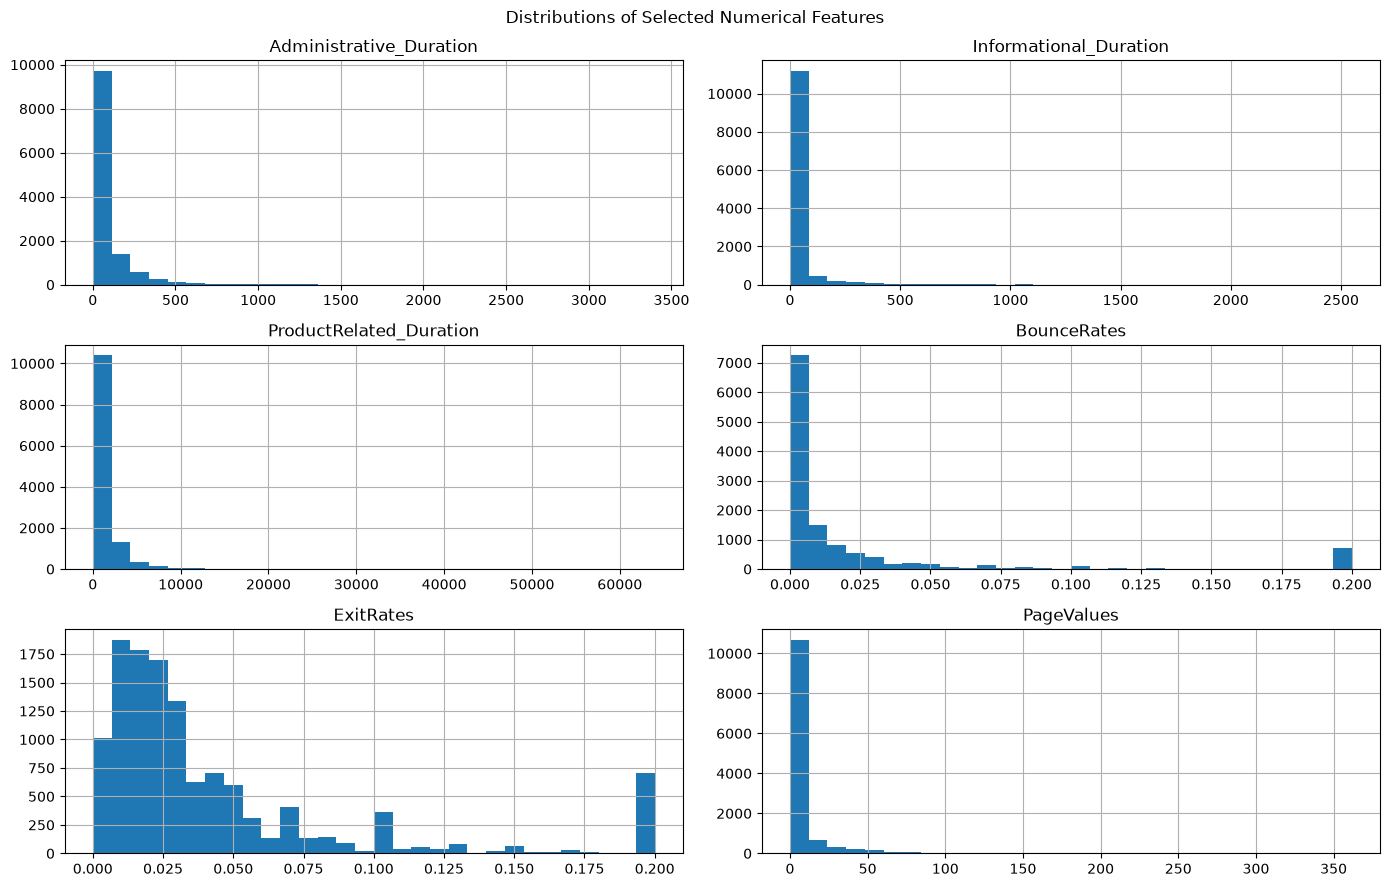

In [35]:
features_to_plot = ["Administrative_Duration","Informational_Duration","ProductRelated_Duration","BounceRates","ExitRates","PageValues"]

df[features_to_plot].hist(figsize=(14, 9), bins=30)
plt.suptitle("Distributions of Selected Numerical Features")
plt.tight_layout()
plt.show()

### 4.5 Comparing avg feature values by revenue

In [36]:
comparison_features = ["PageValues","ProductRelated_Duration","ProductRelated","BounceRates","ExitRates"]

display(df.groupby("Revenue")[comparison_features].mean().T.rename(columns={False: "No purchase", True: "Purchase"}))

Revenue,No purchase,Purchase
PageValues,1.975998,27.264518
ProductRelated_Duration,1069.987809,1876.209615
ProductRelated,28.714642,48.210168
BounceRates,0.025317,0.005117
ExitRates,0.047378,0.019555


## 5. Feature preparation

### 5.1 Defining x and y

In [37]:
target = "Revenue"

X = df.drop(columns=[target])
y = df[target].astype(int)

print("Features:", X.shape[1])
print("Target classes:", sorted(y.unique()))

Features: 17
Target classes: [np.int64(0), np.int64(1)]


### 5.2 Defining feature types

In [38]:
categorical_cols = X.select_dtypes(include=["object", "category", "bool", "str", "string"]).columns.tolist()

numerical_cols = X.select_dtypes(include=np.number).columns.tolist()

print("Categorical columns:", categorical_cols)
print("Numerical columns:", numerical_cols)

assert len(categorical_cols) + len(numerical_cols) == X.shape[1]

Categorical columns: ['Month', 'VisitorType', 'Weekend']
Numerical columns: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']


### 5.3 Train/Test split

In [39]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)
print("Training purchase rate:", round(y_train.mean(), 4))
print("Test purchase rate:", round(y_test.mean(), 4))

Training set: (9864, 17)
Test set: (2466, 17)
Training purchase rate: 0.1547
Test purchase rate: 0.1549


### 5.4 Preprocessing

In [40]:
numeric_pipeline = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])

categorical_pipeline = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),("onehot", OneHotEncoder(handle_unknown="ignore"))])

preprocessor = ColumnTransformer([("numeric", numeric_pipeline, numerical_cols),("categorical", categorical_pipeline, categorical_cols)])

### 6. à vous !